In [1]:
!pip install numpy matplotlib yfinance scipy

import numpy as np
import yfinance
from matplotlib import pyplot as plt

  Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_x86_64.whl.metadata (62 kB)
Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_x86_64.whl (22.7 MB)


In [52]:
#yfinance.Ticker("AMZN").option_chain().calls

In [5]:
data = yfinance.download("AMZN", start="2025-01-01", end="2026-01-01")
close = data["Close"]

[*********************100%***********************]  1 of 1 completed


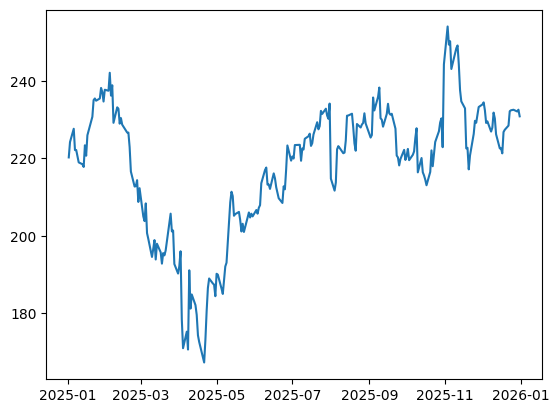

In [21]:
plt.plot(close)

[0.0001888] [0.0216269]


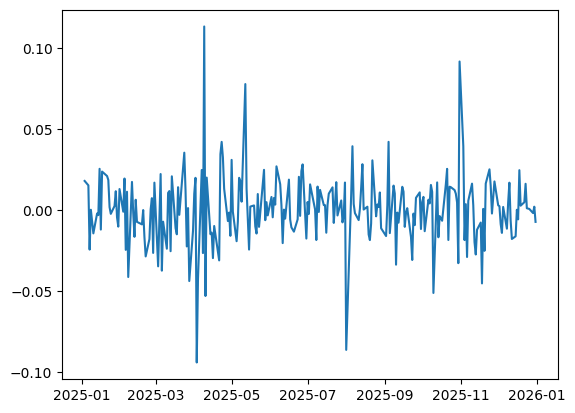

In [6]:
log_returns = np.log(close/close.shift(1)).iloc[1:]
mu = log_returns.mean().values
sigma = log_returns.std().values

print(mu, sigma)

plt.plot(log_returns)

In [ ]:
T = 252
N = 1000
r = 0.05/T # 5% annually

K = 230

In [7]:
def MC_simulation(T, N, mu, sigma, close):
    dt = 1
    Z = np.random.standard_normal(size=(T, N))
    returns = np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
    
    S0 = close.iloc[-1].values[0]
    paths = S0*np.cumprod(returns, axis=0)

    return paths

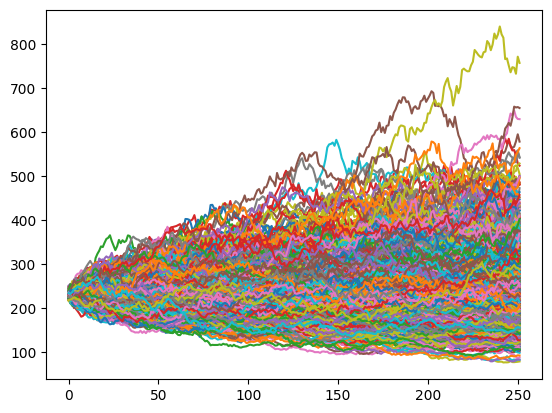

In [28]:
paths = MC_simulation(T, N, r, sigma, close) 

plt.plot(paths)
plt.show()

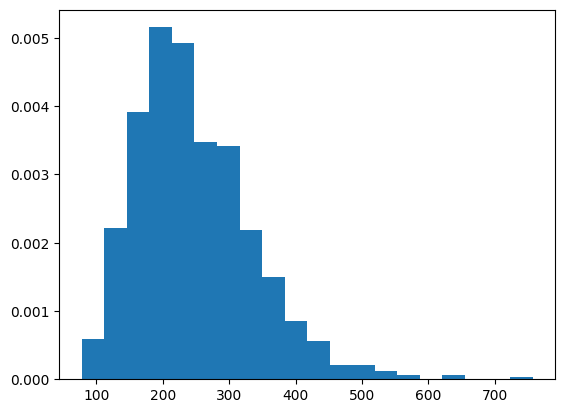

In [29]:
"""
X = paths[-1, :]


sigma = X.std()

x = np.linspace(X.min(), X.max(), 500)

pdf = 1 / np.sqrt(2*np.pi*sigma**2) * np.exp(
    -0.5 * (x-mu)**2 / sigma**2
)
"""
plt.hist(paths[-1, :], density=True, bins=20)
#plt.plot(x, pdf, c="orange", lw=2)
plt.show()

## European Option Pricing with Black-Scholes

In [53]:
def monte_carlo_pricing(N, r, sigma, T, K, close):
    S0 = close.iloc[-1].values[0]
    Z = np.random.standard_normal(N)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    
    payoff = np.maximum(ST - K, 0)
    price = np.exp(-r*T) * np.mean(payoff)

    return price

37.405953770053884


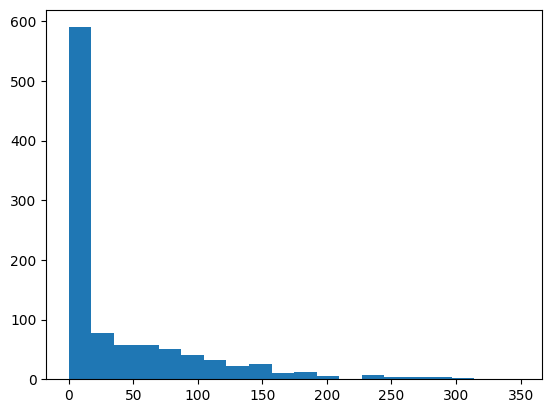

In [54]:
price = monte_carlo_pricing(N, r, sigma, T, K, close)

print(price)
plt.hist(payoff, bins=20)
plt.show()

In [177]:
# We implement black scholes formula for european option to compare the value with the mc method
from scipy.stats import norm

d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)

C = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
bs_price = C[0]

print(f"Call option price by Black-Scholes formula: {round(bs_price, 4)}")

Call option price by Black-Scholes formula: 37.026


In [192]:
Nvalues = [250, 1000, 10_000, 100_000, 1_000_000]

for N in Nvalues:
    price = monte_carlo_pricing(N, r, sigma, T, K, close)
    print(f"Iterations: {N:<7} | MC price: {round(price, 4):<7} | Error {round(price-bs_price, 4):<7} | Error (%): {abs(round((price-bs_price)/bs_price, 3))}")


Iterations: 250     | MC price: 37.5397 | Error 0.5137  | Error (%): 0.014
Iterations: 1000    | MC price: 37.4851 | Error 0.4591  | Error (%): 0.012
Iterations: 10000   | MC price: 37.3714 | Error 0.3455  | Error (%): 0.009
Iterations: 100000  | MC price: 37.0612 | Error 0.0352  | Error (%): 0.001
Iterations: 1000000 | MC price: 36.947  | Error -0.079  | Error (%): 0.002


## American Options: Longstaff–Schwartz Algorithm

In [62]:
def exercise(X, K):
    return np.maximum(K - X, 0)

In [92]:
X = paths[-1,:]
Y = exercise(X, K)
xplot = np.linspace(np.min(X), np.max(X), N)

p = np.polynomial.Chebyshev.fit(X, Y, 4)

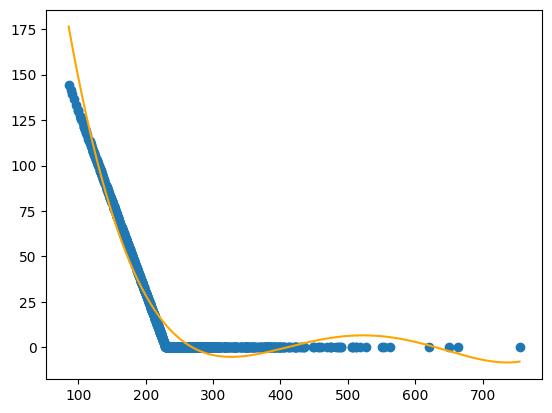

In [93]:
plt.scatter(X, Y)
plt.plot(xplot, p(xplot), c="orange")

In [83]:
dt = 1
#K = 270
deg = 4

Chat_list = [] # Remember to reverse it
tau = np.full(N, T-1, dtype=int)
for t in range(T-2, 0, -1):
    
    X = paths[t,:]
    V = np.exp(-r*(tau-t)*dt)*exercise(paths[tau, np.arange(N)], K)

    itm = X < K
    if itm.sum() > deg+1: # Check that it has enough ITM trajectories to have a good fit
        C_hat = np.polynomial.Chebyshev.fit(X[itm], V[itm], deg) # We want to fit only the ITM part
        tau[itm & (C_hat(X) < K - X)] = t
        Chat_list.append(C_hat)
    else:
        Chat_list.append(None)

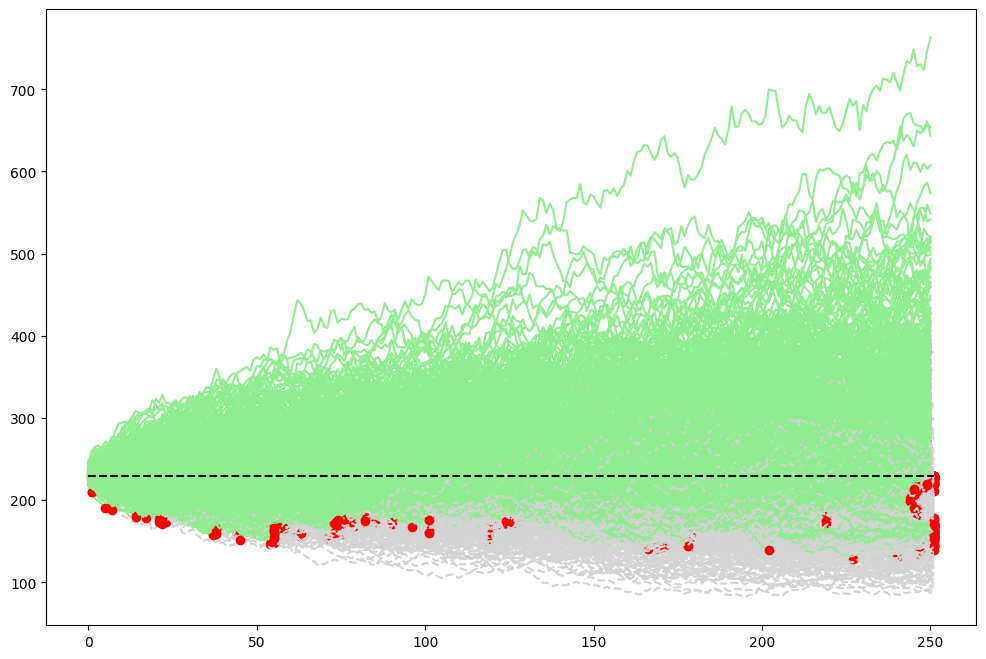

In [84]:
plt.figure(figsize=(12, 8))

for idx in range(paths.shape[1]):
    exercise_time = tau[idx]
    path = paths[:,idx]
    plt.plot(range(exercise_time, T), path[exercise_time:], c="lightgrey", linestyle="--")
    plt.plot(range(exercise_time), path[:exercise_time], c="lightgreen")
    
    if path[exercise_time] < K:
        plt.scatter(exercise_time, path[exercise_time], c="red", zorder=2)

plt.plot(np.arange(T), K*np.ones(T), linestyle="--", c="black")

In [87]:
european = np.exp(-r*T)*np.mean(np.maximum(K - paths[-1,:], 0))
american = 1/N * np.sum(np.exp(-r*(tau+1)*dt)*np.maximum(K - paths[tau, np.arange(N)], 0))

print(european)
print(american)

25.01111454479811
26.480399615407777


In [89]:
#np.exp(-r*T)*np.mean(np.maximum(paths[-1,:] - K, 0))

np.float64(37.53162474791024)

In [86]:
print(american - european)

1.469285070609665
